In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

In [3]:
df = pd.read_csv("student_lifestyle_dataset.csv")

In [4]:
print("Dataset:")
print(df)

Dataset:
      Student_ID  Study_Hours_Per_Day  Extracurricular_Hours_Per_Day  \
0              1                  6.9                            3.8   
1              2                  5.3                            3.5   
2              3                  5.1                            3.9   
3              4                  6.5                            2.1   
4              5                  8.1                            0.6   
...          ...                  ...                            ...   
1995        1996                  6.5                            0.2   
1996        1997                  6.3                            2.8   
1997        1998                  6.2                            0.0   
1998        1999                  8.1                            0.7   
1999        2000                  9.0                            1.7   

      Sleep_Hours_Per_Day  Social_Hours_Per_Day  \
0                     8.7                   2.8   
1                     8.

In [7]:
numeric_df = df.select_dtypes(include='number').drop(
    columns=['Student_ID'],
    errors='ignore'
)
scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(numeric_df)
normalized_df = pd.DataFrame(
    normalized_data,
    columns=numeric_df.columns
)
print("Normalized Dataset:")
print(normalized_df.round(2))
print("\nMinimum values:")
print(normalized_df.min().round(2))
print("\nMaximum values:")
print(normalized_df.max().round(2))

Normalized Dataset:
      Study_Hours_Per_Day  Extracurricular_Hours_Per_Day  Sleep_Hours_Per_Day  \
0                    0.38                           0.95                 0.74   
1                    0.06                           0.88                 0.60   
2                    0.02                           0.98                 0.84   
3                    0.30                           0.52                 0.44   
4                    0.62                           0.15                 0.30   
...                   ...                            ...                  ...   
1995                 0.30                           0.05                 0.48   
1996                 0.26                           0.70                 0.76   
1997                 0.24                           0.00                 0.24   
1998                 0.62                           0.18                 0.52   
1999                 0.80                           0.42                 0.46   

      S

In [8]:
scaler = StandardScaler()
standardized_data = scaler.fit_transform(numeric_df)
standardized_df = pd.DataFrame(
    standardized_data,
    columns=numeric_df.columns
)
print("Standardized Dataset:")
print(standardized_df.round(2))
print("\nMean of each feature:")
print(standardized_df.mean().round(2))
print("\nStandard deviation of each feature:")
print(standardized_df.std(ddof=0).round(2))

Standardized Dataset:
      Study_Hours_Per_Day  Extracurricular_Hours_Per_Day  Sleep_Hours_Per_Day  \
0                   -0.40                           1.57                 0.82   
1                   -1.53                           1.31                 0.34   
2                   -1.67                           1.65                 1.16   
3                   -0.69                           0.10                -0.21   
4                    0.44                          -1.20                -0.69   
...                   ...                            ...                  ...   
1995                -0.69                          -1.55                -0.07   
1996                -0.83                           0.70                 0.89   
1997                -0.90                          -1.72                -0.89   
1998                 0.44                          -1.12                 0.07   
1999                 1.07                          -0.25                -0.14   

     

PCA Transformed Data:
       PC1   PC2
0     0.56 -1.69
1    -0.90 -2.31
2    -1.29 -1.80
3    -1.35  0.14
4     0.07  1.96
...    ...   ...
1995 -1.09  1.45
1996 -1.05 -1.16
1997 -2.44  2.39
1998  0.02  0.17
1999  1.68  0.81

[2000 rows x 2 columns]

Explained Variance Ratio:
[0.3583568  0.22725407]

Total Variance Retained:
0.5856108725399022


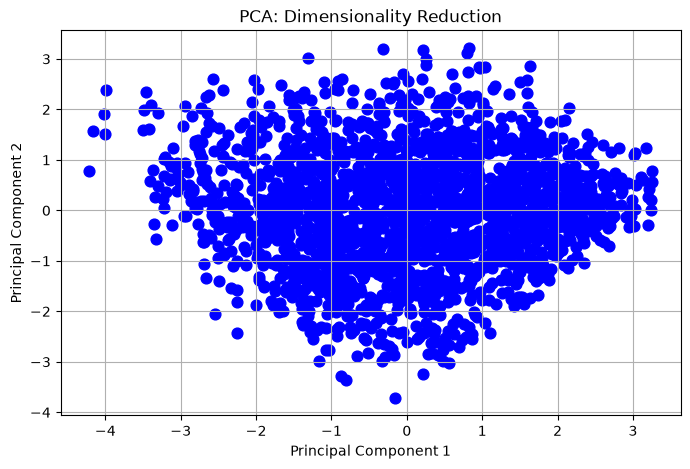

In [9]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df)
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)
pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)
print("PCA Transformed Data:")
print(pca_df.round(2))
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)
print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())
plt.figure(figsize=(8, 5))
plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    s=60
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Dimensionality Reduction")
plt.grid(True)
plt.show()

In [10]:
print("Original Dataset Shape:", numeric_df.shape)
print("Normalized Dataset Shape:", normalized_df.shape)
print("Standardized Dataset Shape:", standardized_df.shape)
print("PCA Dataset Shape:", pca_df.shape)
print("\nTotal Variance Retained:")
print(round(pca.explained_variance_ratio_.sum(), 4))

Original Dataset Shape: (2000, 6)
Normalized Dataset Shape: (2000, 6)
Standardized Dataset Shape: (2000, 6)
PCA Dataset Shape: (2000, 2)

Total Variance Retained:
0.5856
